# Análise de drift e ablação causal

Este notebook interpreta os relatórios versionados produzidos por `run_drift_simulation.py` e `run_causal_ablation.py`. A análise usa dados reais UCI; os lotes são simulados e as labels de performance são reveladas na simulação, ao contrário da produção real.

A ablação compara um mecanismo por vez com o controle M01, com seed 42 e mesmo tamanho de lote. Reamostragem muda necessariamente a população selecionada. M04/M06 são apresentados separadamente para revelar interação e masking, não como intervenções isoladas.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

drift_summary = json.loads(Path("../reports/drift/drift_summary.json").read_text(encoding="utf-8"))
causal = json.loads(Path("../reports/drift/causal_ablation.json").read_text(encoding="utf-8"))
assert drift_summary["source"] == causal["source"] == "real"
display(
    pd.Series(
        {
            "seed": causal["seed"],
            "rows_per_batch": causal["rows_per_batch"],
            "source": causal["source"],
        },
        name="experiment",
    )
)

seed                42
rows_per_batch    2400
source            real
Name: experiment, dtype: object

## Resultados dos lotes M01–M06

PSI define a severidade de drift de distribuição. KS D mede distância entre CDFs e o p-valor é informativo, mas com amostras grandes pode apontar diferenças pequenas. AUC e recall só confirmam degradação quando labels estão disponíveis.

In [2]:
rows = []
for batch_id, batch in drift_summary["batches"].items():
    performance = batch.get("performance", {})
    rows.append(
        {
            "lote": batch_id,
            "mecanismo": batch["narrative"],
            "features_driftadas": ", ".join(batch.get("drifted", [])) or "nenhuma",
            "PSI_score": batch.get("columns", {}).get("score", {}).get("psi"),
            "AUC": performance.get("auc"),
            "Δ AUC vs referência": performance.get("auc_change"),
            "recall inadimplentes": performance.get("recall_default"),
            "alerta performance": batch.get("performance_alert"),
            "expectativa atendida": batch.get("expectation_met"),
        }
    )
display(pd.DataFrame(rows).set_index("lote").round(4))

,mecanismo,features_driftadas,PSI_score,AUC,Δ AUC vs referência,recall inadimplentes,alerta performance,expectativa atendida
lote,,,,,,,,
M01,"Mes normal - lote de controle, sem perturbacao",nenhuma,0.0090,0.7496,0.0001,0.5845,False,True
M02,"Inflacao comeca - faturas 10% maiores, mesmo r...",nenhuma,0.0060,0.7489,-0.0006,0.5825,False,True
M03,"Novos perfis - mais clientes jovens, inflacao ...",AGE,0.0113,0.7654,0.0160,0.6221,False,True
M04,Aperto de credito - M03 com mais atrasos e lim...,"LIMIT_BAL, PAY_0, AGE",0.1276,0.7930,0.0435,0.7419,False,True
M05,Concept drift - clientes em dia e endividados ...,nenhuma,0.0090,0.6821,-0.0674,0.4620,True,True
M06,Crise - aperto de credito (M04) e concept drif...,"LIMIT_BAL, PAY_0, AGE",0.1276,0.7286,-0.0209,0.6383,False,True


## Efeito causal: mecanismos isolados contra M01

Cada cenário da tabela é uma intervenção declarada em `configs/drift_scenarios.yaml`; nenhum mecanismo é hardcoded na lógica. As diferenças são descritivas para esta amostra controlada, não estimativas causais de produção nem intervalos de confiança.

,"features PSI ≥ 0,10",Δ AUC,Δ recall,Δ aprovação,Δ inadimplência
intervenção,,,,,
inflation_only,nenhuma,-0.0007,-0.0020,-0.0021,0.0000
younger_profiles_only,AGE,0.0142,0.0240,-0.0079,0.0004
delayed_profiles_only,PAY_0,0.0588,0.1573,-0.1404,0.1033
lower_limits_only,LIMIT_BAL,-0.0076,-0.0233,0.0000,0.0000
concept_drift_only,nenhuma,-0.0675,-0.1225,0.0000,0.0704


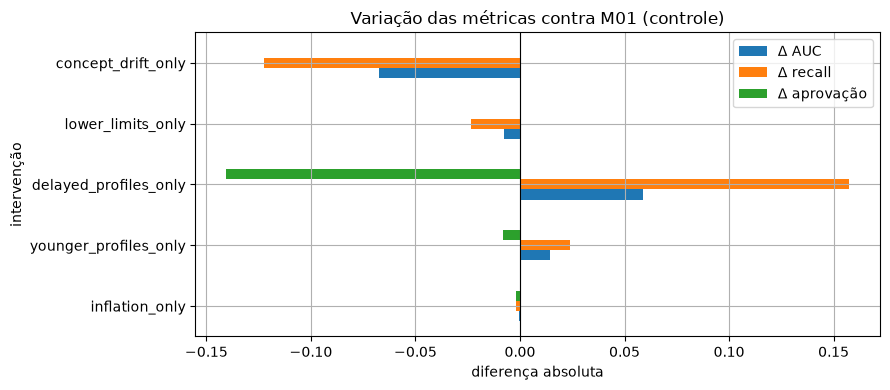

In [3]:
intervention_rows = []
for name, result in causal["interventions"].items():
    delta = result["delta_vs_m01"]
    intervention_rows.append(
        {
            "intervenção": name,
            "features PSI ≥ 0,10": ", ".join(result["drifted"]) or "nenhuma",
            "Δ AUC": delta["auc"],
            "Δ recall": delta["recall_default"],
            "Δ aprovação": delta["approval_rate"],
            "Δ inadimplência": delta["default_rate"],
        }
    )
interventions = pd.DataFrame(intervention_rows).set_index("intervenção")
display(interventions.round(4))
interventions[["Δ AUC", "Δ recall", "Δ aprovação"]].plot.barh(figsize=(9, 4), grid=True)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Variação das métricas contra M01 (controle)")
plt.xlabel("diferença absoluta")
plt.tight_layout()
plt.show()

## Interação e limitações

- A inflação nominal isolada quase não altera a AUC; o KS detecta mudança nas faturas, mas o PSI fica abaixo do limiar operacional.
- A reamostragem de clientes jovens altera a feature de população `AGE`, mas a AUC melhora levemente; drift não implica degradação.
- O aperto isolado aumenta atrasos e reduz limites; métricas de performance melhoram neste dataset, apesar do drift e da queda na aprovação.
- O concept drift isolado mantém as features e scores estáveis, mas reduz AUC/recall. Na crise M06, a carteira com maior inadimplência mascara parte da queda contra M01. Contra M04, o Δ de AUC quantifica essa interação.

A simulação é controlada e sintética no sentido causal: não prova que mecanismos reais produzirão as mesmas magnitudes. Ver decisões, limites e resultados em `docs/DRIFT.md` e `docs/ARQUITETURA.md`.